In [12]:
from dotenv import load_dotenv
load_dotenv()

True

In [13]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

## Understanding `State` (explained simply)

Think of **State** as the **shared memory** that travels through your graph. Every node reads from it and writes back to it.

```python
class State(TypedDict):
    messages: Annotated[list, add_messages]
```

Breaking it down piece by piece:

| Part | Meaning |
|------|---------|
| `TypedDict` | A dictionary with a fixed set of keys and known value types. `State` is just a `dict` under the hood, e.g. `{"messages": [...]}`. |
| `messages` | The one key in our state. It holds the conversation (a list of messages). |
| `list` | The type of the value — a plain Python list. |
| `Annotated[list, add_messages]` | Attaches extra info to the type. Here it tells LangGraph: "when a node returns new messages, **append** them to the list instead of **replacing** it." |

### The key idea: reducers
`add_messages` is a **reducer** — a function that decides *how* to merge a node's output into the existing state.

- **Without** a reducer → new value **overwrites** the old value.
- **With** `add_messages` → new messages are **added on top** of the existing ones (so the chat history grows).

That's why a chatbot can "remember" the whole conversation: each turn appends to `messages` rather than wiping it.


In [5]:
# Example 1: A State is really just a dict with a "messages" key.
# Messages are usually LangChain message objects.
from langchain_core.messages import HumanMessage, AIMessage

example_state: State = {
    "messages": [
        HumanMessage(content="Hi, who are you?"),
        AIMessage(content="I'm a chatbot built with LangGraph!"),
    ]
}

example_state


{'messages': [HumanMessage(content='Hi, who are you?', additional_kwargs={}, response_metadata={}),
  AIMessage(content="I'm a chatbot built with LangGraph!", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]}

In [5]:
# Example 2: See the reducer in action.
# add_messages(existing, new) returns the MERGED list (append behavior).
existing = [HumanMessage(content="What's 2 + 2?")]
new = [AIMessage(content="It's 4.")]

merged = add_messages(existing, new)
merged  # notice the old message is kept and the new one is added


[HumanMessage(content="What's 2 + 2?", additional_kwargs={}, response_metadata={}, id='4e20b64c-0171-4f04-939c-15a395bf9d32'),
 AIMessage(content="It's 4.", additional_kwargs={}, response_metadata={}, id='0d202083-6db2-4201-9769-256a3d20d66a', tool_calls=[], invalid_tool_calls=[])]

### Why `add_messages` matters: append vs overwrite

Two nodes each return one message. Compare what the final state holds:

- **With `add_messages`**: each node's messages are **appended**.
- **Without it**: each node's output **overwrites** the list, so earlier messages are lost.

Note: this only merges updates *within one run*. Remembering across separate `invoke` calls needs a checkpointer.

In [ ]:
## State Graph Example with Reducer and Without Reducer
## State 1
class WithReducer(TypedDict):
    messages: Annotated[list, add_messages]  # append

## State 2
class WithoutReducer(TypedDict):
    messages: list  # overwrite

def node_a(state):
    return {"messages": [("ai", "reply from A")]}

def node_b(state):
    return {"messages": [("ai", "reply from B")]}

def run(StateType):
    g = StateGraph(StateType)
    g.add_node("a", node_a)
    g.add_node("b", node_b)
    g.add_edge(START, "a")
    g.add_edge("a", "b")
    g.add_edge("b", END)
    out = g.compile().invoke({"messages": [("user", "Hi")]})
    return [(m[0], m[1]) if isinstance(m, tuple) else (m.type, m.content) for m in out["messages"]]

print("WITH add_messages   :", run(WithReducer))
print("WITHOUT add_messages:", run(WithoutReducer))

WITH add_messages   : [('human', 'Hi'), ('ai', 'reply from A'), ('ai', 'reply from B')]
WITHOUT add_messages: [('ai', 'reply from B')]


### State can hold more than just messages

Your `State` can have **any keys you need**. Only keys annotated with a reducer (like `add_messages`) get special merge behavior — everything else is **overwritten** on each update.

Below are a few different shapes a state might take.


In [6]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [6]:
# Example 3: Different State shapes for different use-cases.

# (a) Chatbot that also tracks the user's name and a turn counter.
class ChatState(TypedDict):
    messages: Annotated[list, add_messages]  # appended
    user_name: str                           # overwritten
    turn_count: int                          # overwritten

sample_a: ChatState = {
    "messages": [HumanMessage(content="Hello!")],
    "user_name": "Alex",
    "turn_count": 1,
}

# (b) A support bot that classifies intent and stores extracted data.
class SupportState(TypedDict):
    messages: Annotated[list, add_messages]
    intent: str                 # e.g. "refund", "complaint"
    is_resolved: bool

sample_b: SupportState = {
    "messages": [HumanMessage(content="I want a refund")],
    "intent": "refund",
    "is_resolved": False,
}

print(sample_a)
print(sample_b)


{'messages': [HumanMessage(content='Hello!', additional_kwargs={}, response_metadata={})], 'user_name': 'Alex', 'turn_count': 1}
{'messages': [HumanMessage(content='I want a refund', additional_kwargs={}, response_metadata={})], 'intent': 'refund', 'is_resolved': False}


Basic ChatBot

In [4]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [ ]:
# Fix SSL "CERTIFICATE_VERIFY_FAILED" on corporate networks:
# make Python trust the Windows certificate store. Run this BEFORE calling the LLM.
import truststore
truststore.inject_into_ssl()

In [13]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")


In [14]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E48C612420>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E48C613380>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [15]:
## Basic LLM call

llm.invoke("Hello, how are you?")

AIMessage(content='Hello! I’m doing great—thanks for asking. How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says: "Hello, how are you?" We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 77, 'total_tokens': 129, 'completion_time': 0.059472479, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.03673627, 'prompt_tokens_details': None, 'queue_time': 0.069590589, 'total_time': 0.096208749}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_34cb00738d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17920-06f8-767b-bb0e-31b08864e50a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 52, 'total_tokens': 129, 'output_token_details': {'reasoning': 25}})

In [16]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [17]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

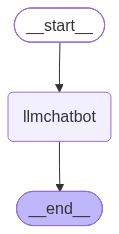

In [18]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [27]:
dict = {"messages":"Hi"}
print(dict["messages"])

Hi


In [36]:
response=graph.invoke({"messages":"Hi, my name is Dhruv"})
response

{'messages': [HumanMessage(content='Hi, my name is Dhruv', additional_kwargs={}, response_metadata={}, id='84142768-6224-4a82-83ed-0c28959f1879'),
  AIMessage(content='Hello Dhruv! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond to user greeting. Provide friendly response. Probably ask how can I help.'}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 79, 'total_tokens': 122, 'completion_time': 0.05077428, 'completion_tokens_details': {'reasoning_tokens': 20}, 'prompt_time': 0.00529212, 'prompt_tokens_details': None, 'queue_time': 0.615035195, 'total_time': 0.0560664}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_92d51d08e5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17932-b3ba-76cc-8b6e-b0dfa19c56d2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 43, 'total_tokens': 122, 'output_to

In [37]:
print(response["messages"][1].content)

Hello Dhruv! 👋 How can I help you today?


In [38]:
response=graph.invoke({"messages":"What is my name ?"})
response

{'messages': [HumanMessage(content='What is my name ?', additional_kwargs={}, response_metadata={}, id='6f9ca598-fbd2-4a19-b1f4-aabbdb05ba14'),
  AIMessage(content='I don’t actually know your name—could you let me know what you’d like me to call you?', additional_kwargs={'reasoning_content': 'The user asks: "What is my name?" We don\'t know their name. According to policy, we should not guess or fabricate. We can ask them. The user is likely expecting a playful or maybe they want us to respond with "I don\'t know" or "I don\'t have that info". We should respond politely, acknowledging we don\'t know and ask for name. That is straightforward.'}, response_metadata={'token_usage': {'completion_tokens': 110, 'prompt_tokens': 76, 'total_tokens': 186, 'completion_time': 0.120661864, 'completion_tokens_details': {'reasoning_tokens': 79}, 'prompt_time': 0.004337322, 'prompt_tokens_details': None, 'queue_time': 0.219795488, 'total_time': 0.124999186}, 'model_name': 'openai/gpt-oss-20b', 'system

#### Chatbot with tools

In [ ]:
# User question --> tool selection (via llm) --> tool execution --> response

In [8]:
from dotenv import load_dotenv
load_dotenv()

True

In [9]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

Internet search example

In [4]:
from langchain_tavily import TavilySearch

tavily_search = TavilySearch(max_results=5)
#tavily_search.invoke("Provide high level learning path for Agentic AI")

Actual Tool calling Chatbot

In [1]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")

In [2]:
## Custom function as tool
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [5]:
tools=[tavily_search,multiply]
llm_with_tool=llm.bind_tools(tools)
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002672629E060>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000026725615C40>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

In [16]:
## simple llm with tool call test
# r = llm_with_tool.invoke("What is 3 times 4?")
# r.content      # probably "12" or similar, so the model answered itself
# r.tool_calls   # []
# r

In [6]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [11]:

## Define State

class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [13]:
## Create all Nodes

## LLM call node
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Tool node for invoking tools
tool_node = ToolNode(tools)

In [14]:
## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)

## In case of tool node, the name should always be "tools" so that conditional edge can correctly route to it
builder.add_node("tools", tool_node)

tools_condition is a ready-made routing function for conditional edges. It looks at the last message in the state and returns the name of the next node:

If the last AIMessage has tool_calls, it returns "tools".
Otherwise it returns END.

In [15]:
## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")
builder.add_edge("tool_calling_llm", END)


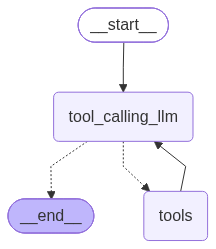

In [16]:
## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [42]:
graph.invoke({"messages": ["what are the latest USCIS news ?"]})

{'messages': [HumanMessage(content='what are the latest USCIS news ?', additional_kwargs={}, response_metadata={}, id='70063006-25a2-421e-9f1c-49ec285fc86a'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need latest USCIS news. Likely need up-to-date info. Use tavily_search.', 'tool_calls': [{'id': 'fc_cb11b39a-cf0c-4494-bf69-99cb190a053d', 'function': {'arguments': '{"query":"latest USCIS news 2026","search_depth":"advanced"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 350, 'total_tokens': 407, 'completion_time': 0.060875547, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.020972378, 'prompt_tokens_details': None, 'queue_time': 0.174564408, 'total_time': 0.081847925}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ef00694abe', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run-

In [21]:
response=graph.invoke({"messages":"What is the recent ai news"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_69db34a8-a97e-467e-87cf-f7b1319b4f48)
 Call ID: fc_69db34a8-a97e-467e-87cf-f7b1319b4f48
  Args:
    query: recent AI news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://siliconangle.com/2026/10/26/cybersecurity-ai-resilience-recovery-thecube-aicybersecurityresiliencesummit", "title": "Cybersecurity in the AI era: Why cyber resilience matters - SiliconANGLE", "content": "A prime example of how AI models have shifted cybersecurity into a new gear can be seen in recent news involving exploits surrounding the PHP programming language, which p

In [20]:
response=graph.invoke({"messages":"What is the recent ai news, also help me provide the multiplication of 5 and 7, provide the multiplication results using tool calls available"})
response['messages'][-1].content
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news, also help me provide the multiplication of 5 and 7, provide the multiplication results using tool calls available
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_b7054932-e71b-4380-b8d9-ac9192d327d1)
 Call ID: fc_b7054932-e71b-4380-b8d9-ac9192d327d1
  Args:
    query: recent AI news
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=XW4D6NguJmA", "title": "Recent News in Artificial Intelligence: Critical Analysis (Featuring Connor Leahy)", "content": "### Description\n23,087 views\nPosted: 2026-10-23\nAI has been in the news a lot lately. Jacob Coxon, former employee at Anthropic and OpenAI, blew the whist

#### Adding Memory In Agentic Graph

In [22]:
response=graph.invoke({"messages":"Hello my name is Dhruv"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Dhruv
================================== Ai Message ==================================

Hello Dhruv! How can I help you today?


In [23]:
response=graph.invoke({"messages":"What is my name ?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name ?
================================== Ai Message ==================================

I’m sorry, but I don’t have any information about your name. Could you let me know what you’d like me to call you?


In [26]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

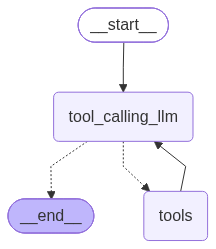

: 

In [ ]:
## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))